In [16]:
import os
import sys
import itertools

import joblib
import pandas as pd
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.plotting import plot_movement_data
from utils.metrics import show_feature_extraction_metrics
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.lof_detector import LOFDetector
from utils.helper_functions import calculate_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'LOF' 
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

In [17]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [18]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


### Load Features from Csv

In [19]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()

assert not np.isnan(X_features).any(), "NaN in features"

## Local Outlier Factor (LOC)

In [20]:
total_trials_unique = features_df.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)
total_samples = len(features_df)
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

print(f"--- Preparation (Feature-Based) ---")
print(f"Total samples analyzed ({TARGET_MOVEMENT}): {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate in CSV (sub + repID): {percentagem_conhecida:.2f}%")

--- Preparation (Feature-Based) ---
Total samples analyzed (Move): 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate in CSV (sub + repID): 5.26%


### Grid Search

In [ ]:
n_neighbors_options = [3, 5, 7, 10, 15, 20]


param_grid = [
    {'n_neighbors': n, 'contamination': s} 
    for n, s in itertools.product(n_neighbors_options, Configs.CONTAMINATION_GRID)
]

loso_results = run_loso_evaluation(
    detector_class=LOFDetector, 
    param_grid=param_grid,
    data_matrix=X_features,                     # all features
    metadata_df=features_df[Configs.META_COLS], # same rows as X_features
    known_outliers_df=outliers_csv,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Statistic Evaluation - Bootstraping

In [22]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [23]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_FEATURE_EXTRACTION_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for LOF - FeatureBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 5
Rejection Rate: 5.26%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  4
Total False Positives (Global): 1
Total False Negatives (Global): 1
Total True Negatives (Global):  89
------------------------------
Blind Precision: 80.00 [50.00–100.00]
Blind Recall:    80.00 [33.33–100.00]
Blind F1-Score:  80.00
Blind F2-Score:  80.00 [38.46–100.00]
Blind MCC:       0.79 [0.50–1.00]
Blind AUPRC:  92.67 [81.78–100.00]
Blind AUROC:   99.56

Total Tuning Time (19 Subjects): 74.2639s
Total Inference Time (19 Subjects): 0.5306s

Overall Best Parameters (Most frequent across folds):
   {'contamination': 0.05, 'n_neighbors': 10}
Occurrences: 13


### Train Model

In [ ]:
best_params = loso_results['Best_Params']
n_neighbors = best_params['n_neighbors']
contamination = best_params['contamination']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

In [25]:
lof_model = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination, n_jobs=-1, metric='euclidean')

# Train mode (oultier = -1, normal = 1)
labels = lof_model.fit_predict(X_features_scaled_full)
features_df['anomaly'] = labels

joblib.dump(lof_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# Resultados
n_outliers = (features_df['anomaly'] == -1).sum()
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(features_df, total_trials)
print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Percentagem de Lixo Detetado (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Percentagem de Lixo Detetado (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 5
Unique Outlier Trials Detected: 5
Percentagem de Lixo Detetado (sub + repID + movID): 5.26%
Percentagem de Lixo Detetado (sub + repID): 5.26%


In [26]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Quem são os outliers reais?")
print(outliers_metadata_df)

Quem são os outliers reais?
    sub  repID  movID
6     2      2      9
15    4      1      9
30    7      1      9
50   11      1      9
55   12      1      9


In [27]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    features_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 5
False Positives (Identified, not in CSV): 0
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 90
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 5/5 (100.00%)
Recall (True Positive Rate): 5/5 (100.00%)
F1-Score: 100.00%
F2-Score: 100.00%


In [28]:
outlier_ids = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['anomaly'] == -1]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; it does not permanently alter the original df if you do not want it to
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


### Plot Things

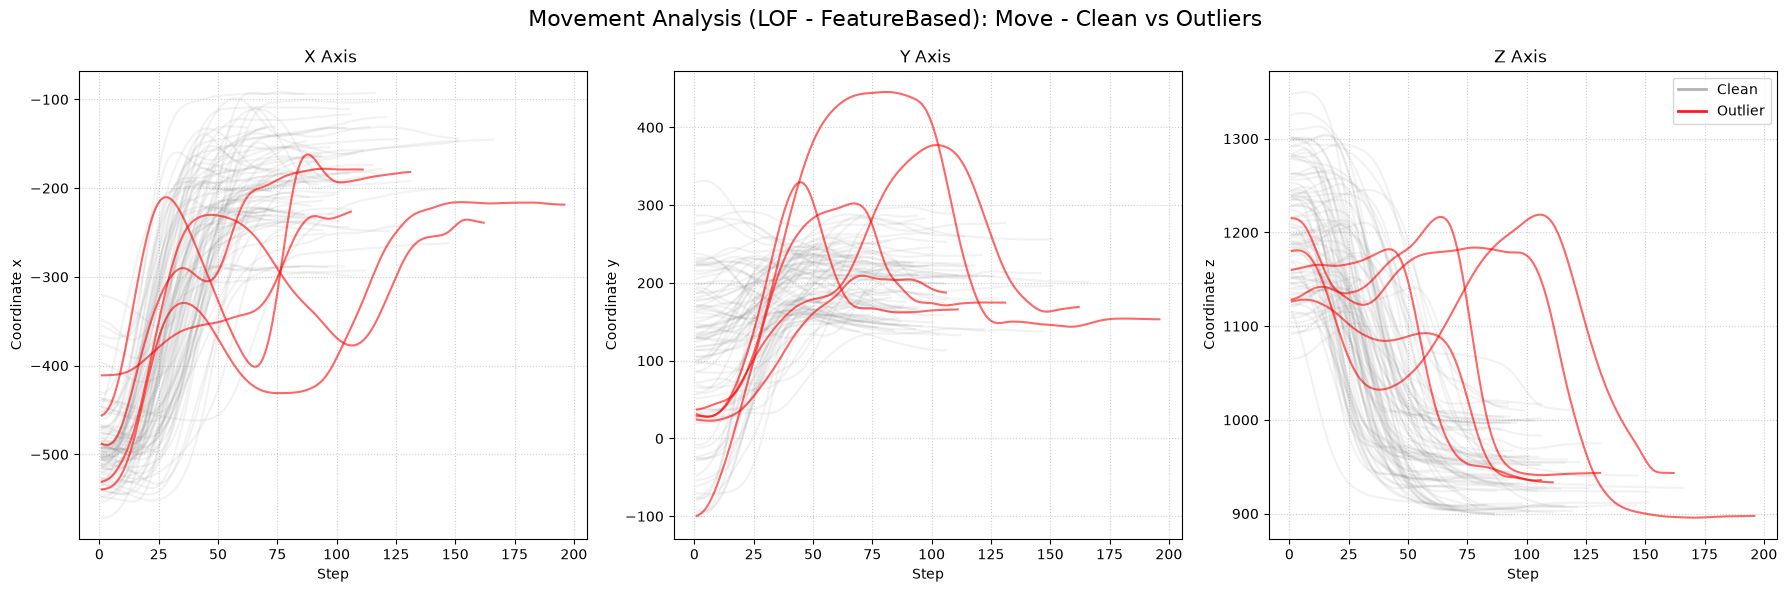

In [29]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [30]:
# Limpeza: remover coluna auxiliar
df.drop(columns=['temp_key'], inplace=True)